In [7]:
import json
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [8]:
root_path = "../"

trizod_filename = os.path.join(root_path, "datasets/cleaned_trizod_dataset.csv")
trizod_df = pd.read_csv(
    trizod_filename,
    index_col="label",
    converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)},
)
df_train = trizod_df[~trizod_df["is_test"]]
# df_test = trizod_df[trizod_df["is_test"]]

In [9]:
filename = "train7.csv"

if not os.path.exists(filename):
    fasta_filename = "train.fasta"
    with open(fasta_filename, "w") as f:
        for label, row in df_train.iterrows():
            f.write(f">{label}\n{row['sequence']}\n")

    subprocess.run(
        [
            "adopt2g-predict",
            "--input",
            fasta_filename,
            "--out",
            filename,  # "--no", "--save"
        ],
        check=True,
    )
    os.remove(fasta_filename)
df_inferred = pd.read_csv(
    filename,
    index_col="label",
    converters={
        "gscores": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.array(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.array(json.loads(x), dtype=float),
    },
)
df_inferred

,sequence,mean_gscore,mean_gscore_lower,mean_gscore_upper,gscores,gscores_lower,gscores_upper
label,,,,,,,
9_1_1_1,XQHADPICNKPCKTHDDCSGAWFCQACWNSARTCGPYVG,0.124289,0.080251,0.187565,"[nan, 0.23300752342477682, 0.32092770417160194...","[nan, 0.08819004480076281, 0.13939637966532398...","[nan, 0.4885274046320433, 0.5795193962695273, ..."
26_1_1_1,MADPNRFRGKDLPVLDQLTDPP,0.606360,0.204961,0.902000,"[0.4899305608524222, 0.49123472376488486, 0.41...","[0.1421127940696213, 0.155847773045521, 0.1525...","[0.8478418186787678, 0.8346765773924546, 0.728..."
32_1_1_1,MKPVTLYDVAEYAGVSYQTVSRVVNQASHVSAKTREKVEAAMAELN...,0.111255,0.077099,0.157953,"[0.2878679030352921, 0.2286728342355607, 0.197...","[0.1037486268663797, 0.14116297998248356, 0.13...","[0.5852196833544826, 0.3484233988827676, 0.287..."
39_1_1_1,XMDPNCSCATDGSCSCAGSCKCKQCKKTSCKKSCCSCCPVGCAKCS...,0.164459,0.110819,0.237138,"[nan, 0.2674081661882255, 0.30507586721565505,...","[nan, 0.17217184695139576, 0.15791445754192152...","[nan, 0.39035963053622064, 0.5068355116069857,..."
41_1_1_1,VFCTCRGFLCGSGERASGSCTINGVRHTLCCRR,0.164306,0.089170,0.283074,"[0.27532452572571114, 0.2220246807679208, 0.19...","[0.09219619882783585, 0.1120159509200037, 0.08...","[0.5869964297463166, 0.39256967556924377, 0.36..."
...,...,...,...,...,...,...,...
53396_1_1_1,GSDQSENVDRGAGSIREAGGAFGKREQAEEERYFRAQSREQLAALK...,0.270769,0.191667,0.367668,"[0.41335873989676925, 0.3612773864465049, 0.41...","[0.05389915445121032, 0.06030763997506922, 0.0...","[0.8971559208377049, 0.8327813311689884, 0.924..."
53398_1_1_1,PAGQPERTLESLLAHLQEQHGLRVRILLHGSALLYAAGWSPEKQAQ...,0.105237,0.073492,0.148495,"[0.3735329769578475, 0.2922921929755219, 0.298...","[0.16451646289656316, 0.19620941280870197, 0.1...","[0.6434413254540363, 0.4112290866276087, 0.503..."
53400_1_1_1,KCGSLGNIHHKPGGGQVEVKSEKLDFKDRVQSKIGSLDNITHVPGG...,0.864882,0.789289,0.916234,"[0.7581526713451106, 0.785637692336557, 0.8660...","[0.25982563796098374, 0.24436300507078526, 0.7...","[0.9655114724420827, 0.9764905475924671, 0.935..."


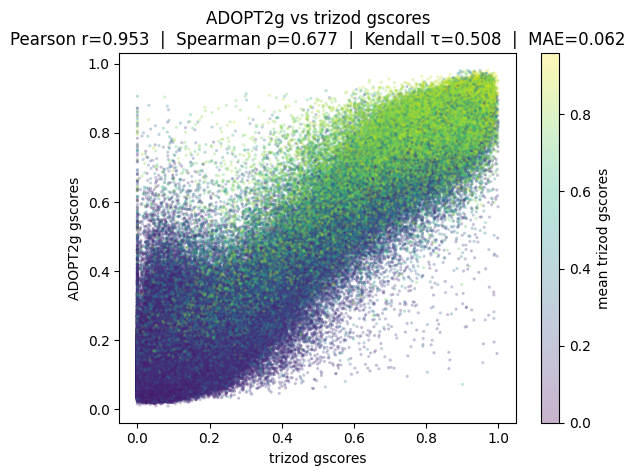

In [10]:
from scipy.stats import kendalltau, pearsonr, spearmanr

mean_trizod_gscores = np.repeat(df_train["gscores"].apply(np.nanmean).values, df_train["gscores"].apply(len).values)
trizod_gscores = np.concatenate(df_train["gscores"].values)
adopt2_gscores = np.concatenate(df_inferred["gscores"].values)
mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

# Compute correlation metrics
pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

# Also compute MAE for prediction accuracy
mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
plt.xlabel("trizod gscores")
plt.ylabel("ADOPT2g gscores")
plt.title(
    f"ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
)
plt.colorbar(label="mean trizod gscores")
plt.show()


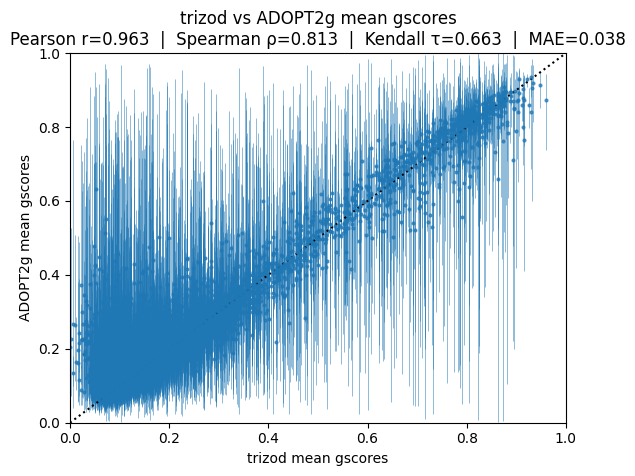

In [11]:
# Compute correlation metrics for mean gscores
pearson_r_mean, _ = pearsonr(df_train["mean_gscore"], df_inferred["mean_gscore"])
spearman_rho_mean, _ = spearmanr(df_train["mean_gscore"], df_inferred["mean_gscore"])
kendall_tau_mean, _ = kendalltau(df_train["mean_gscore"], df_inferred["mean_gscore"])
mae_mean = np.mean(np.abs(df_train["mean_gscore"].values - df_inferred["mean_gscore"].values))

plt.errorbar(
    df_train["mean_gscore"],
    df_inferred["mean_gscore"],
    yerr=[
        df_inferred["mean_gscore"] - df_inferred["mean_gscore_lower"],
        df_inferred["mean_gscore_upper"] - df_inferred["mean_gscore"],
    ],
    fmt="o",
    markersize=2,
    elinewidth=0.5,
    alpha=0.7,
    capsize=0,
)
plt.xlabel("trizod mean gscores")
plt.ylabel("ADOPT2g mean gscores")
plt.title(
    f"trizod vs ADOPT2g mean gscores\nPearson r={pearson_r_mean:.3f}  |  Spearman ρ={spearman_rho_mean:.3f}  |  Kendall τ={kendall_tau_mean:.3f}  |  MAE={mae_mean:.3f}",
)
plt.axline((0.5, 0.5), slope=1, color="k", ls=":")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


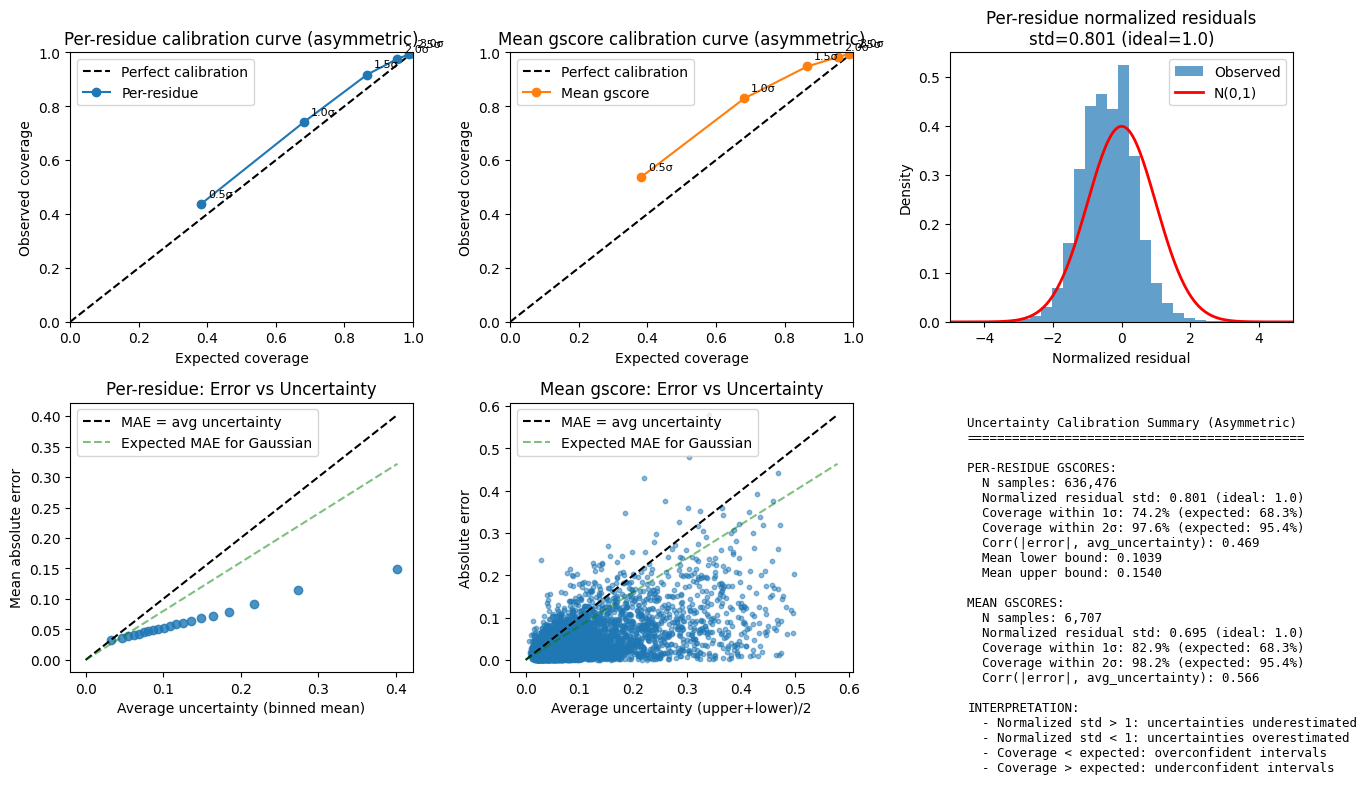

In [12]:
# Uncertainty calibration analysis with asymmetric intervals
# For well-calibrated uncertainties, ~68% of true values should fall within the 1σ interval, ~95% within 2σ

# --- Per-residue uncertainty calibration (asymmetric) ---
trizod_gscores = np.concatenate(df_train["gscores"].values)
pred_gscores = np.concatenate(df_inferred["gscores"].values)
pred_gscores_lower = np.concatenate(df_inferred["gscores_lower"].values)
pred_gscores_upper = np.concatenate(df_inferred["gscores_upper"].values)

# Compute asymmetric uncertainties (distance from prediction to bounds)
pred_err_lower = pred_gscores - pred_gscores_lower  # positive: how far below pred the lower bound is
pred_err_upper = pred_gscores_upper - pred_gscores  # positive: how far above pred the upper bound is

# Mask for valid values
mask = (
    np.isfinite(trizod_gscores)
    & np.isfinite(pred_gscores)
    & np.isfinite(pred_gscores_lower)
    & np.isfinite(pred_gscores_upper)
    & (pred_err_lower > 0)
    & (pred_err_upper > 0)
)
true_vals = trizod_gscores[mask]
pred_vals = pred_gscores[mask]
err_lower = pred_err_lower[mask]
err_upper = pred_err_upper[mask]

# Compute z-scores using asymmetric bounds
# Use upper bound for positive residuals (true > pred), lower bound for negative residuals
residuals = true_vals - pred_vals
z_scores = np.where(
    residuals >= 0,
    residuals / err_upper,  # true above pred: normalize by upper uncertainty
    residuals / err_lower,  # true below pred: normalize by lower uncertainty (gives negative z)
)

# For binned analysis, use average uncertainty width
avg_err = (err_lower + err_upper) / 2

# Calibration: fraction of points within n-scaled intervals
n_sigmas = np.array([0.5, 1, 1.5, 2, 2.5, 3])
from scipy.stats import norm

expected_coverage = np.array([norm.cdf(n) - norm.cdf(-n) for n in n_sigmas])

# For asymmetric intervals: check if true is within [pred - n*err_lower, pred + n*err_upper]
observed_coverage_residue = np.array(
    [np.mean((true_vals >= pred_vals - n * err_lower) & (true_vals <= pred_vals + n * err_upper)) for n in n_sigmas],
)

# --- Mean gscore uncertainty calibration (asymmetric) ---
true_mean = df_train["mean_gscore"].values
pred_mean = df_inferred["mean_gscore"].values
pred_mean_lower = df_inferred["mean_gscore_lower"].values
pred_mean_upper = df_inferred["mean_gscore_upper"].values

# Asymmetric uncertainties for mean
mean_err_lower = pred_mean - pred_mean_lower
mean_err_upper = pred_mean_upper - pred_mean

mask_mean = (
    np.isfinite(true_mean)
    & np.isfinite(pred_mean)
    & np.isfinite(pred_mean_lower)
    & np.isfinite(pred_mean_upper)
    & (mean_err_lower > 0)
    & (mean_err_upper > 0)
)
residuals_mean = true_mean[mask_mean] - pred_mean[mask_mean]
z_scores_mean = np.where(
    residuals_mean >= 0,
    residuals_mean / mean_err_upper[mask_mean],
    residuals_mean / mean_err_lower[mask_mean],
)

observed_coverage_mean = np.array(
    [
        np.mean(
            (true_mean[mask_mean] >= pred_mean[mask_mean] - n * mean_err_lower[mask_mean])
            & (true_mean[mask_mean] <= pred_mean[mask_mean] + n * mean_err_upper[mask_mean]),
        )
        for n in n_sigmas
    ],
)

# --- Plotting ---
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# 1. Calibration curve - Per-residue
ax = axes[0, 0]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_residue, "o-", color="tab:blue", label="Per-residue")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Per-residue calibration curve (asymmetric)")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_residue[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 2. Calibration curve - Mean gscore
ax = axes[0, 1]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_mean, "o-", color="tab:orange", label="Mean gscore")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Mean gscore calibration curve (asymmetric)")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_mean[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 3. Z-score histogram - Per-residue (asymmetric)
ax = axes[0, 2]
ax.hist(z_scores, bins=100, density=True, alpha=0.7, label="Observed")
x_range = np.linspace(-5, 5, 200)
ax.plot(x_range, norm.pdf(x_range), "r-", lw=2, label="N(0,1)")
ax.set_xlabel("Normalized residual")
ax.set_ylabel("Density")
ax.set_title(f"Per-residue normalized residuals\nstd={np.std(z_scores):.3f} (ideal=1.0)")
ax.legend()
ax.set_xlim(-5, 5)

# 4. Error vs predicted uncertainty - Per-residue (binned)
ax = axes[1, 0]
abs_errors = np.abs(residuals)
# Bin by average uncertainty
n_bins = 20
err_bins = np.percentile(avg_err, np.linspace(0, 100, n_bins + 1))
bin_centers = []
mean_errors = []
for i in range(n_bins):
    in_bin = (avg_err >= err_bins[i]) & (avg_err < err_bins[i + 1])
    if np.sum(in_bin) > 10:
        bin_centers.append(np.mean(avg_err[in_bin]))
        mean_errors.append(np.mean(abs_errors[in_bin]))
ax.scatter(bin_centers, mean_errors, alpha=0.8)
max_val = max(max(bin_centers), max(mean_errors))
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = avg uncertainty")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Average uncertainty (binned mean)")
ax.set_ylabel("Mean absolute error")
ax.set_title("Per-residue: Error vs Uncertainty")
ax.legend()

# 5. Error vs predicted uncertainty - Mean gscore
ax = axes[1, 1]
abs_errors_mean = np.abs(residuals_mean)
avg_err_mean = (mean_err_lower[mask_mean] + mean_err_upper[mask_mean]) / 2
ax.scatter(avg_err_mean, abs_errors_mean, alpha=0.5, s=10)
max_val = max(avg_err_mean.max(), abs_errors_mean.max())
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = avg uncertainty")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Average uncertainty (upper+lower)/2")
ax.set_ylabel("Absolute error")
ax.set_title("Mean gscore: Error vs Uncertainty")
ax.legend()

# 6. Summary statistics table
ax = axes[1, 2]
ax.axis("off")
summary_text = f"""Uncertainty Calibration Summary (Asymmetric)
{"=" * 45}

PER-RESIDUE GSCORES:
  N samples: {len(z_scores):,}
  Normalized residual std: {np.std(z_scores):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_residue[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_residue[3] * 100:.1f}% (expected: 95.4%)
  Corr(|error|, avg_uncertainty): {np.corrcoef(abs_errors, avg_err)[0, 1]:.3f}
  Mean lower bound: {np.mean(err_lower):.4f}
  Mean upper bound: {np.mean(err_upper):.4f}

MEAN GSCORES:
  N samples: {len(z_scores_mean):,}
  Normalized residual std: {np.std(z_scores_mean):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_mean[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_mean[3] * 100:.1f}% (expected: 95.4%)
  Corr(|error|, avg_uncertainty): {np.corrcoef(abs_errors_mean, avg_err_mean)[0, 1]:.3f}

INTERPRETATION:
  - Normalized std > 1: uncertainties underestimated
  - Normalized std < 1: uncertainties overestimated
  - Coverage < expected: overconfident intervals
  - Coverage > expected: underconfident intervals
"""
ax.text(0.05, 0.95, summary_text, transform=ax.transAxes, fontsize=9, verticalalignment="top", fontfamily="monospace")

plt.tight_layout()
plt.show()
